# Project 6 – UPS Monitoring Non-Compliance Audit

**Source:** `data/raw/apc_ups_sites.csv`, a site-by-site audit of the **UPS (battery backup) units** that protect network and server racks across the company's Canadian sites.
The standard: every UPS should be **connected to the network and reporting to the monitoring tool (PRTG)**, so IT is alerted before a power cut takes a site offline.
A UPS that is offline, has no usable network port, or can't be checked is **non-compliant**.

| Column | What it holds |
|---|---|
| Item | Audit item number |
| Status | Monitoring status: Online, Offline, No Netwk Port, Smart NtwkPort, No UPS, … |
| Site, City | Site name and its 3-letter site code |
| APC Connected (two columns) | Whether the UPS is connected (Yes/No) and how many units are connected |
| UPS Availability, Network Card Compatible | Whether a UPS exists and has a usable network card |
| Brand of UPS, Model Number, APC Serial No. | Hardware details |
| Notes, Additional Notes, USP location Server | Free-text notes from the technicians |

**Note on privacy:** people's names, internal IP addresses and UPS serial numbers in this public copy are replaced with placeholders. Sites, statuses and models are real.

### Business questions
1. **BQ1 Compliance rate:** what share of UPS units, and of sites, are monitored?
2. **BQ2 Reasons:** why are units non-compliant?
3. **BQ3 Fixability:** which problems can be fixed remotely, and which need hardware or a site visit?
4. **BQ4 Sites:** which sites carry the most risk?
5. **BQ5 Hardware:** do brand or model explain the failures?
6. **BQ6 Audit quality:** is the audit sheet itself reliable?

In [1]:
# Import the libraries we need
import os
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 40)

# One simple chart style for the whole notebook
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110, "savefig.dpi": 150,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "axes.edgecolor": "#8a8985", "axes.titleweight": "bold", "axes.titlesize": 13,
    "font.size": 10, "legend.frameon": False,
})
# Colours with one job each, used the same way in every chart
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"     # categories, in this order
GREEN, RED, GREY = "#0ca30c", "#d03b3b", "#b5b4ae"       # good / problem / not applicable
os.makedirs("../images", exist_ok=True)                   # charts are saved here for the README

## 1. Load and understand the data

In [2]:
# Saved from Excel on Windows, so read it with the cp1252 encoding
raw = pd.read_csv("../data/raw/apc_ups_sites.csv", encoding="cp1252", dtype=str)
print(raw.shape)
print([repr(c) for c in raw.columns])     # repr shows the hidden trailing spaces in some names
raw.head()

(72, 18)
["'Item'", "'Notes'", "'APC Connected '", "'Status'", "'No. of APC'", "'APC Connected'", "'Site'", "'City'", "'Site POC'", "'UPS Availability'", "'Network Card Compatible'", "'Brand of UPS'", "'All plugs connected'", "'Model Number'", "'APC Serial No.'", "'USP location Server'", "'Additional Notes'", "'Unnamed: 17'"]


,Item,Notes,APC Connected,Status,No. of APC,APC Connected,Site,City,Site POC,UPS Availability,Network Card Compatible,Brand of UPS,All plugs connected,Model Number,APC Serial No.,USP location Server,Additional Notes,Unnamed: 17
0,33,NaN,Yes,Online,1,1,Barrie,BRR,Person U2,Yes,Available,APS,Yes,NaN,NaN,NaN,NaN,NaN
1,34,NaN,NaN,Online,NaN,1,Blackfoot,Blackfoot,Person T,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-,NaN
2,20,Existing UPS to be replaced. Person ...,NaN,Offline,NaN,0,Brampton,BMT,Person Z/ Person Q,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,21,Person Z2 confirmed that the UPS has...,Yes,Offline,1,1,Brandon,BRD,NaN,Yes,Available,APC,NaN,NaN,NaN,NaN,NaN,NaN
4,35,NaN,Yes,Online,1,1,Calgary,CLG,Person X2,Yes,Available,APC,NaN,SMT2200RM2UTW,ASE024CF5C85,Warehouse Supervisors Office. IP: 10...,-,NaN


## 2. Validate the data

In [3]:
# Check 1: the last row is a "total" row, not a UPS
raw.tail(2)[["Item", "Status", "No. of APC", "APC Connected", "Site"]]

,Item,Status,No. of APC,APC Connected,Site
70,66,Smart NtwkPort,1,NaN,Yarmouth
71,total,NaN,55,70,NaN


In [4]:
# Check 2: two columns are both called "APC Connected" - one with a trailing space (Yes/No), one without (a count)
print("'APC Connected ' (with space):", raw["APC Connected "].value_counts(dropna=False).to_dict())
print("'APC Connected' (count):      ", raw["APC Connected"].value_counts(dropna=False).to_dict())
print("'No. of APC':                 ", raw["No. of APC"].value_counts(dropna=False).to_dict())

'APC Connected ' (with space): {'Yes': 35, 'No': 21, nan: 16}
'APC Connected' (count):       {'1': 44, nan: 13, '2': 10, '0': 3, '6': 1, '70': 1}
'No. of APC':                  {'1': 55, nan: 16, '55': 1}


In [5]:
# Check 3: item numbers - blanks and repeats
print("Blank item numbers:", raw["Item"].isna().sum())
print("Repeated item numbers:", raw["Item"].value_counts()[lambda s: s > 1].to_dict())

Blank item numbers: 2
Repeated item numbers: {'61': 4}


In [6]:
# Check 4: the same status written different ways, and brand typos
print(raw["Status"].value_counts(dropna=False).to_dict())
print(raw["Brand of UPS"].value_counts(dropna=False).to_dict())

{'Online': 32, 'No Netwk Port': 14, 'Offline': 11, 'Smart NtwkPort ': 5, 'No UPS': 3, 'Could not check': 2, nan: 2, 'No Battery in UPS': 1, 'No Ntwk Port': 1, 'Closed': 1}
{'APC': 33, nan: 21, 'APS': 17, 'TRIPP-LITE': 1}


In [7]:
# Check 5: values in the wrong column - Model Number should only hold model codes
models = raw["Model Number"].dropna()
models[~models.str.strip().str.fullmatch(r"[A-Za-z0-9\-]+")]

5                                IP: 10.x.x.x
15    Person E and Person D3 will assist m...
51            unable to locate the data sheet
Name: Model Number, dtype: str

In [8]:
# Check 6: site codes - most are 3 capital letters, some are written in full
codes = raw["City"].dropna()
codes[~codes.str.fullmatch(r"[A-Z]{3}")].unique()

<StringArray>
['Blackfoot', 'EDMUNDSTON', 'SAULT STE MARIE', 'Yarmouth']
Length: 4, dtype: str

### Validation summary
* **The last row is a "total" row** (55 / 70), not a UPS. It is removed, leaving **71 UPS records at 52 sites**.
* **Two columns share the name "APC Connected"**: one has a hidden trailing space and holds Yes/No, the other holds a count. They are renamed `Connected_YesNo` and `Connected_Count`.
* **Item numbers:** 2 rows have no item number, and item `61` is used for 4 different UPS units at Weston.
* **The same status is spelt different ways** (`No Netwk Port` / `No Ntwk Port`, `Smart NtwkPort ` with a trailing space). They are standardised. 2 rows have no status.
* **Brand typo:** `APS` appears 17 times and is clearly APC (the model codes are APC's). It is corrected.
* **Values in the wrong column:** 3 Model Number cells hold an IP address, a technician's note or "unable to locate the data sheet" instead of a model code.
* **4 site codes are written in full** (`Blackfoot`, `EDMUNDSTON`, `SAULT STE MARIE`, `Yarmouth`) instead of 3 letters. They are shortened.
* **An empty column** at the end of the sheet is dropped.

## 3. Clean the data

In [9]:
# 1) Drop the total row and tidy the column names
df = raw[raw["Item"].fillna("").str.lower() != "total"].copy()
# Rename the two "APC Connected" columns BEFORE trimming names, otherwise they end up with the same name
df = df.rename(columns={"APC Connected ": "Connected_YesNo", "APC Connected": "Connected_Count"})
df.columns = df.columns.str.strip()
df = df.drop(columns=["Unnamed: 17"])          # an empty column at the end of the sheet

# 2) Trim spaces in every text column
for col in df.columns:
    df[col] = df[col].str.strip()

# 3) Standardise status spellings, and fix the brand typo ("APS" is APC)
df["Status"] = df["Status"].replace({"No Ntwk Port": "No Netwk Port", "Smart NtwkPort": "Smart Netwk Port"}).fillna("Not recorded")
df["Brand of UPS"] = df["Brand of UPS"].replace({"APS": "APC"})

# 4) Standardise site codes (3 letters) where they were written in full
df["City"] = df["City"].replace({"Blackfoot": "BLK", "EDMUNDSTON": "EDM", "SAULT STE MARIE": "SSM", "Yarmouth": "YAR"})

# 5) The compliance rule: a UPS is compliant only if its status is Online (reporting to PRTG)
df["compliant"] = df["Status"].eq("Online")
print("UPS records:", len(df), "| sites:", df["Site"].nunique())
df[["Item", "Site", "City", "Status", "Brand of UPS", "compliant"]].head()

UPS records: 71 | sites: 52


,Item,Site,City,Status,Brand of UPS,compliant
0,33,Barrie,BRR,Online,APC,True
1,34,Blackfoot,BLK,Online,NaN,True
2,20,Brampton,BMT,Offline,NaN,False
3,21,Brandon,BRD,Offline,APC,False
4,35,Calgary,CLG,Online,APC,True


In [10]:
# 6) Group every non-compliant status into a reason and say how it can be fixed
reason = {
    "Offline": ("Connected but not reporting", "Remote fix (network / PRTG)"),
    "No Netwk Port": ("No network port on the UPS", "Hardware: add a network card"),
    "Smart Netwk Port": ("Wrong network card type (Smart port)", "Hardware: swap the network card"),
    "No UPS": ("No UPS installed", "Hardware: buy a UPS"),
    "No Battery in UPS": ("No battery in the UPS", "Hardware: replace the battery"),
    "Could not check": ("Could not be checked", "Site visit"),
    "Closed": ("Site closing", "No action (site closing)"),
    "Not recorded": ("Status not recorded", "Site visit"),
}
df["reason"] = df["Status"].map(lambda s: reason.get(s, ("Compliant", "None"))[0])
df["fix"] = df["Status"].map(lambda s: reason.get(s, ("Compliant", "None"))[1])

os.makedirs("../data/processed", exist_ok=True)
df.to_csv("../data/processed/ups_sites_clean.csv", index=False)
df["Status"].value_counts()

Status
Online               32
No Netwk Port        15
Offline              11
Smart Netwk Port      5
No UPS                3
Could not check       2
No Battery in UPS     1
Closed                1
Not recorded          1
Name: count, dtype: int64

## 4. Analysis

### BQ1 – Compliance rate

In [11]:
units = len(df)
ok = df["compliant"].sum()
print(f"UPS records compliant: {ok} of {units} ({ok / units:.1%})")

# A site is compliant only if every UPS it has is online
site_ok = df.groupby("Site")["compliant"].all()
print(f"Sites fully compliant: {site_ok.sum()} of {len(site_ok)} ({site_ok.mean():.1%})")

UPS records compliant: 32 of 71 (45.1%)
Sites fully compliant: 24 of 52 (46.2%)


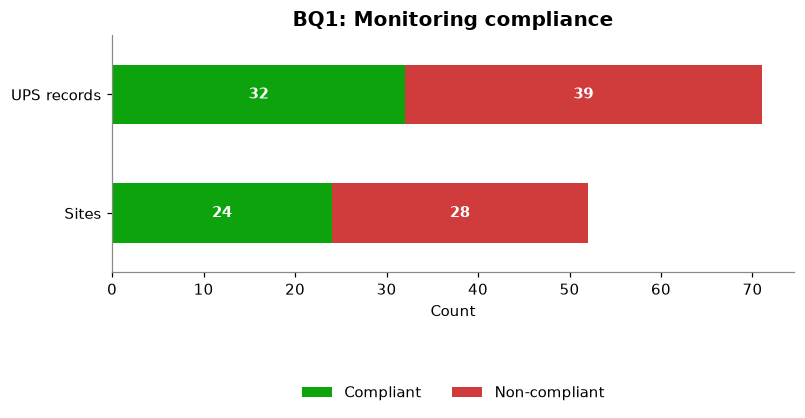

In [12]:
summary = pd.DataFrame({"Compliant": [ok, site_ok.sum()], "Non-compliant": [units - ok, (~site_ok).sum()]},
                       index=["UPS records", "Sites"])
ax = summary.plot(kind="barh", stacked=True, color=[GREEN, RED], figsize=(8, 2.8), title="BQ1: Monitoring compliance")
for container in ax.containers:
    ax.bar_label(container, label_type="center", color="white", fontweight="bold")
ax.invert_yaxis(); ax.set_xlabel("Count"); ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.6), ncol=2)
plt.savefig("../images/01_bq1_compliance.png", bbox_inches="tight"); plt.show()

**Finding:** Only **32 of 71 UPS units (45.1%) are online and monitored**. At site level it is the same picture: **24 of 52 sites (46.2%)** have every UPS reporting. More than half the network is protected by a UPS that IT can't see.

**Recommendation:** Set a target (for example 90% of units monitored within one quarter) and report the compliance rate monthly from this cleaned table.

### BQ2 – Reasons for non-compliance

reason
No network port on the UPS              15
Connected but not reporting             11
Wrong network card type (Smart port)     5
No UPS installed                         3
Could not be checked                     2
No battery in the UPS                    1
Site closing                             1
Status not recorded                      1
Name: count, dtype: int64


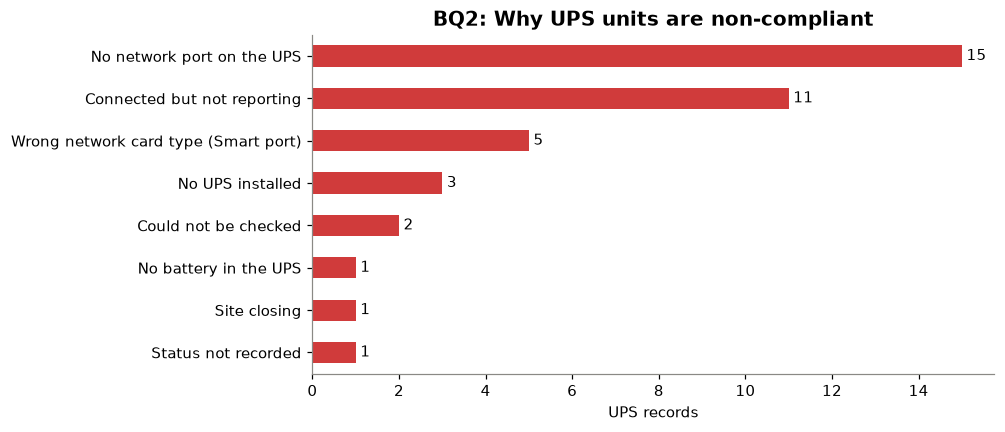

In [13]:
reasons = df[~df["compliant"]]["reason"].value_counts()
print(reasons)
ax = reasons.plot(kind="barh", color=RED, figsize=(8, 4), title="BQ2: Why UPS units are non-compliant")
ax.bar_label(ax.containers[0], padding=3); ax.invert_yaxis(); ax.set_xlabel("UPS records"); ax.set_ylabel("")
plt.savefig("../images/02_bq2_reasons.png", bbox_inches="tight"); plt.show()

**Finding:** Of the 39 non-compliant units, the biggest reasons are **no network port on the UPS (15)** and **connected but not reporting (11)**. Next come the **wrong network card type, a "Smart" port (5)**, **no UPS installed (3)**, could not be checked (2), no battery (1), site closing (1) and status not recorded (1).

**Recommendation:** Work the list by reason, not by site: each reason has one fix that can be applied across many sites at once.

### BQ3 – What it takes to fix

fix
Hardware: add a network card       15
Remote fix (network / PRTG)        11
Hardware: swap the network card     5
Site visit                          3
Hardware: buy a UPS                 3
Hardware: replace the battery       1
No action (site closing)            1
Name: count, dtype: int64
Need new hardware: 24 | remote fix: 11


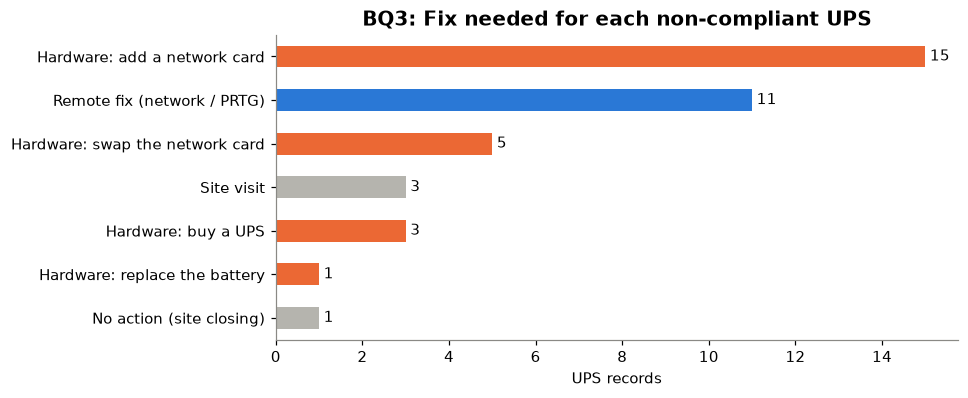

In [14]:
fixes = df[~df["compliant"]]["fix"].value_counts()
print(fixes)
hardware = fixes[fixes.index.str.startswith("Hardware")].sum()
print("Need new hardware:", hardware, "| remote fix:", fixes.get("Remote fix (network / PRTG)", 0))

colours = [ORANGE if f.startswith("Hardware") else (BLUE if f.startswith("Remote") else GREY) for f in fixes.index]
ax = fixes.plot(kind="barh", color=colours, figsize=(8, 3.6), title="BQ3: Fix needed for each non-compliant UPS")
ax.bar_label(ax.containers[0], padding=3); ax.invert_yaxis(); ax.set_xlabel("UPS records"); ax.set_ylabel("")
plt.savefig("../images/03_bq3_fixes.png", bbox_inches="tight"); plt.show()

**Finding:** **11 units can be fixed remotely**: they are connected but not reporting, so the problem is the switch port, VLAN or PRTG set-up. **24 need hardware**: 15 network cards, 5 replacement cards for the Smart-port units, 3 new UPS units and 1 battery. 3 need a site visit, and 1 site is closing.

**Recommendation:** Do the 11 remote fixes first; it's quick, cheap, and lifts compliance from 45% to about 61%. Then raise one purchase order for 20 network cards, 3 UPS units and 1 battery.

### BQ4 – Sites carrying the most risk

                       units  non_compliant
Site                                       
Calgary                    9              7
Weston                     6              4
London                     4              3
Chatham                    2              1
Toronto - King Street      2              1
Brampton                   1              1
Brandon                    1              1
Castlegar                  1              1
Charlottetown-PEI          1              1
Edmonton                   1              1
Edmundston                 1              1
Fredericton                1              1


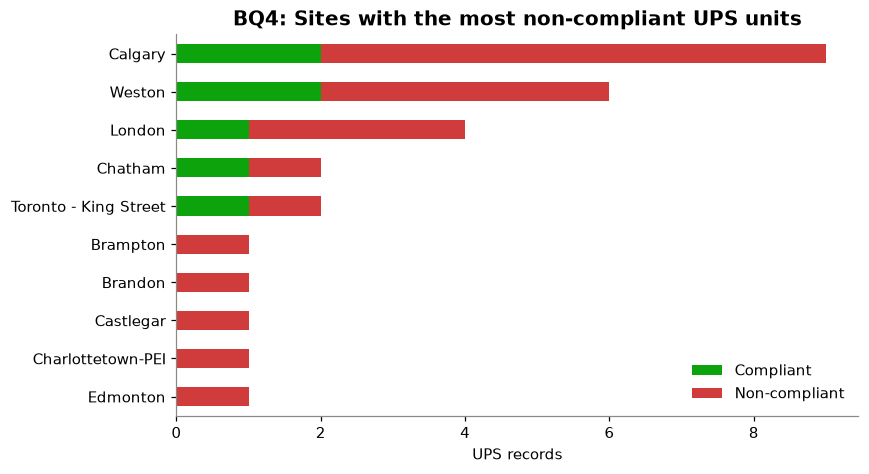

In [15]:
by_site = df.groupby("Site").agg(units=("compliant", "size"), non_compliant=("compliant", lambda s: (~s).sum()))
by_site = by_site[by_site["non_compliant"] > 0].sort_values(["non_compliant", "units"], ascending=False)
print(by_site.head(12))

top = by_site.head(10)
ax = top[["non_compliant"]].assign(compliant=top["units"] - top["non_compliant"])[["compliant", "non_compliant"]].plot(
    kind="barh", stacked=True, color=[GREEN, RED], figsize=(8, 4.5), title="BQ4: Sites with the most non-compliant UPS units")
ax.invert_yaxis(); ax.set_xlabel("UPS records"); ax.set_ylabel(""); ax.legend(["Compliant", "Non-compliant"])
plt.savefig("../images/04_bq4_sites.png", bbox_inches="tight"); plt.show()

**Finding:** Risk is concentrated. **Calgary has 7 of its 9 UPS units non-compliant**, **Weston 4 of 6** and **London 3 of 4**. Together these three sites hold 14 of the 39 non-compliant units (36%). The other 25 are spread one per site.

**Recommendation:** Send one technician to Calgary, Weston and London with network cards. Those three visits fix over a third of the problem.

### BQ5 – Does the hardware explain it?

In [16]:
# Compliance by brand (blank brand = not recorded)
print(pd.crosstab(df["Brand of UPS"].fillna("Not recorded"), df["compliant"].map({True: "Compliant", False: "Non-compliant"}), margins=True))

# Model families: the first 3 letters of an APC model code (SMT, SMX, SRT, SUA, SMTL ...)
df["model_family"] = df["Model Number"].str.extract(r"^(SMTL|SMT|SMX|SRT|SUA)")[0]
fam = pd.crosstab(df["model_family"].fillna("Unknown / not recorded"), df["Status"])
fam

compliant     Compliant  Non-compliant  All
Brand of UPS                               
APC                  18             32   50
Not recorded         14              6   20
TRIPP-LITE            0              1    1
All                  32             39   71


Status,Closed,Could not check,No Battery in UPS,No Netwk Port,No UPS,Not recorded,Offline,Online,Smart Netwk Port
model_family,,,,,,,,,
SMT,0,0,0,1,0,0,2,2,3
SMTL,0,1,0,0,0,0,0,0,0
SMX,0,0,1,3,0,0,4,5,2
SRT,0,0,0,5,0,0,0,0,0
SUA,0,0,0,2,0,0,0,0,0
Unknown / not recorded,1,1,0,4,3,1,5,25,0


In [17]:
# Network port problems by model family
port = df[df["Status"].isin(["No Netwk Port", "Smart Netwk Port"])]
print(port["model_family"].value_counts(dropna=False))

model_family
SRT    5
SMX    5
SMT    4
NaN    4
SUA    2
Name: count, dtype: int64


**Finding:** Every non-compliant unit with a recorded brand is APC except one Tripp-Lite, so brand is not the issue. **Model family is:** all 5 **SRT** and both **SUA** units have no network port, and the 5 Smart-port failures are **SMT and SMX** models. Most of the 20 units with no brand recorded are online, which suggests healthy sites were simply audited less thoroughly.

**Recommendation:** Buy the network card that matches each model family (SRT, SUA, SMT, SMX), and standardise new purchases on models with a built-in network port.

### BQ6 – Is the audit sheet reliable?

All plugs connected         28.2
APC Serial No.              47.9
Model Number                54.9
Brand of UPS                71.8
Network Card Compatible     73.2
Connected_YesNo             78.9
UPS Availability            78.9
Status                     100.0
dtype: float64


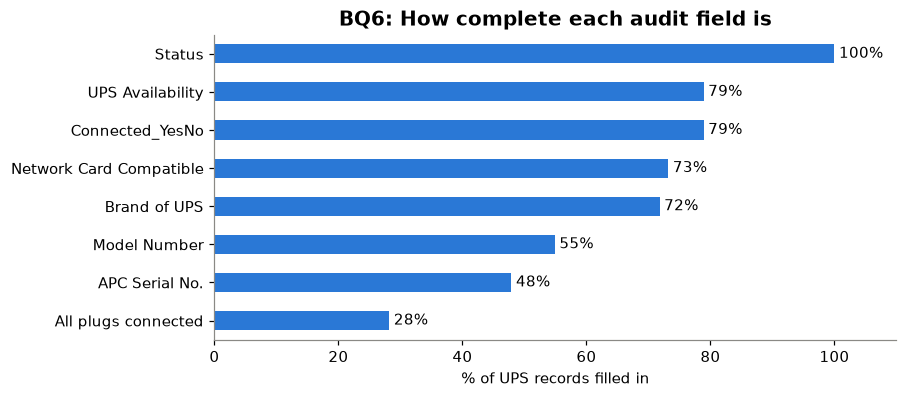

In [18]:
# How complete is each field? (share of UPS records with a value)
fields = ["Status", "Connected_YesNo", "UPS Availability", "Network Card Compatible", "Brand of UPS", "Model Number", "APC Serial No.", "All plugs connected"]
filled = (df[fields].notna().mean() * 100).round(1).sort_values()
print(filled)
ax = filled.plot(kind="barh", color=BLUE, figsize=(8, 3.6), title="BQ6: How complete each audit field is")
ax.bar_label(ax.containers[0], fmt="%.0f%%", padding=3); ax.set_xlabel("% of UPS records filled in"); ax.set_xlim(0, 110)
plt.savefig("../images/05_bq6_completeness.png", bbox_inches="tight"); plt.show()

In [19]:
# Do "Connected = Yes" and "Status = Online" agree?
print(pd.crosstab(df["Connected_YesNo"].fillna("blank"), df["Status"]))

Status           Closed  Could not check  No Battery in UPS  No Netwk Port  No UPS  Not recorded  Offline  Online  Smart Netwk Port
Connected_YesNo                                                                                                                    
No                    0                2                  1             14       2             0        0       0                 2
Yes                   0                0                  0              1       0             0       10      21                 3
blank                 1                0                  0              0       1             1        1      11                 0


**Finding:** The audit sheet is incomplete. **Only 28% of units have "All plugs connected" filled in**, 48% have a serial number, 55% a model number and 72% a brand. It also contradicts itself: **10 units are marked Connected = Yes but are Offline**, and 11 online units have the Connected field blank.

**Recommendation:** Turn the audit into a form with required fields (status, brand, model, serial) and drop-down lists, so every site is recorded the same way and statuses can't be spelt differently.

## 5. Summary
| # | Question | Answer |
|---|---|---|
| BQ1 | Compliance rate | **32 of 71 units (45.1%)**; 24 of 52 sites (46.2%) |
| BQ2 | Reasons | No network port **15**, connected but not reporting **11**, wrong card **5** |
| BQ3 | Fixability | **11 remote fixes**; **24 need hardware** |
| BQ4 | Sites | Calgary 7, Weston 4, London 3 = **36%** of the problem |
| BQ5 | Hardware | SRT/SUA lack a port; SMT/SMX have the wrong (Smart) card |
| BQ6 | Audit quality | Plugs field 28% complete; **10 "Yes but Offline"** contradictions |

**Main message:** less than half the UPS fleet is monitored. A quick round of 11 remote fixes, then one hardware order and three site visits, would take compliance from 45% to over 90%.